# Demo of simulating the random Lotka-Volterra model

The ODE we simulate is
$$
\frac{{\rm d} y_i(t)}{{\rm d}t} =  y_i(t) \left( r_i - \sum_{j=1}^S a_{ij} y_j(t) \right) + m_i
$$
and we want to draw each pair $(a_{ij}, a_{ji})$ (for $i\neq j$) as two ${\rm Normal}(\mu,\sigma)$ random variates with a correlation $\gamma$, and a fixed diagonal $a_{ii}$ (that we typically set to 1).


## Imports

In [9]:
import sys
sys.path.append("../src")
import glv                          # the glv package 
import jax.numpy as jnp             # fast array computations, with numpy-like syntax 
import matplotlib.pyplot as plt
import jax
import seaborn as sns




## Run a single simulation

### Generate parameters

In [2]:
S = 500             # number of species

# Make the random matrix

mu = 0.5#0.5                # mean interaction
sig = 0.3#0.3               # std of interaction
gam = 0#0.                 # correlation
diag = 1                    # value on the diagonal; if different between species: diag = jnp.array([a11, a22, ...])
key = None                  # no seed; draw on system entropy


In [ ]:

A = glv.gaussian_randmat(S, mu, sig, gam, diag, key)


In [3]:

# Other parameters
#r_vec = jnp.concat([jnp.array([1.] * (S - 1)), jnp.array([100])])  
r = 1#r_vec  # growth rates; if different between species: r = jnp.array([r1, r2, ...])
m = 1e-8#1e-8                # immigration rate; can also be given as array

In [4]:

# Keep an interesting matrix: uncomment, pick a name, and run (saved in saved_matrices.json)
#glv.save_randmat("A1", key, S, mu, sig, gam, diag)

# Get it back later, instead of generating a new one (S must match the saved matrix)
A = glv.load_randmat("A1")

### Integrate
We use the default method and arguments, which transforms to log-abundance space, and integrates with adaptive step-size Runge-Kutta of order 4/5, using default tolerances.  

In [5]:
N = 1000         # number of samples to record along the trajectory
dT = 1.               # continuous time interval between sampling
y0 = jnp.ones(S)/S      # initial condition

In [6]:
ts, ys = glv.solve(N, dT, r, A, m, y0)

### Plot the results

The parameters used puts us in the chaotic phase; abundances should fluctuate wildly

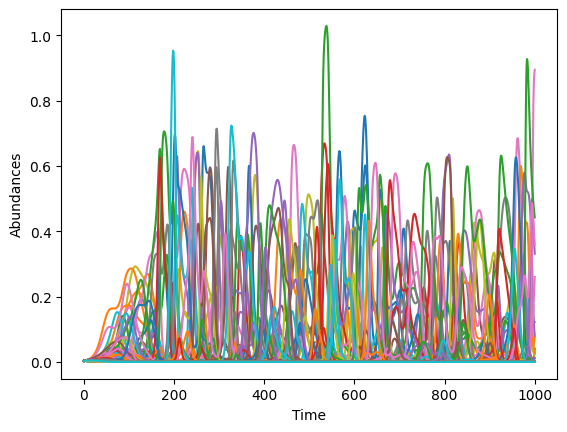

In [7]:
# plot linear abundances

plt.plot(ts, ys)
plt.xlabel("Time")
plt.ylabel("Abundances")
plt.show()

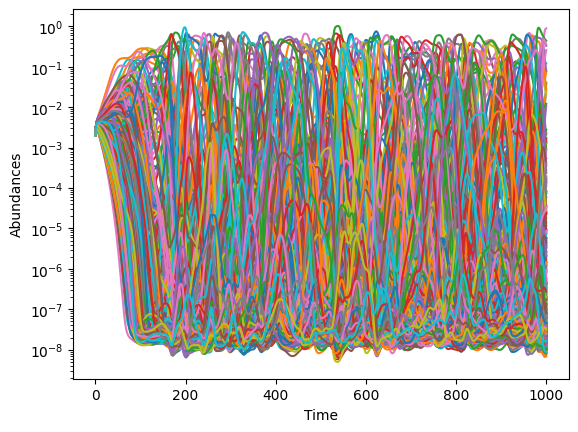

In [8]:
# plot log abundances

plt.plot(ts, ys)
plt.yscale('log')
plt.xlabel("Time")
plt.ylabel("Abundances")
plt.show()

### Notes on solvers and boundary behaviour

The following solvers can be used
- The default `solve` aka `solve_log_RK45` - explicit solver in log-space. Integrating in log-space improves numerical stability/stiffness.
- `solve_RK45` - explicit solver in linear space
- `solve_implicit34`- implicit solver in linear space
- any diffrax adaptive step-size ODE solver can be used; see `make_adaptive_solve`  

If there is positive immigration, there is a limit to how rare a species can become in practise. If there is no immigration, `m=0.`, some species may asymptotically approach 0 abundance, which is problematic:
- Realistically, species should be considered extinct below some small threshold. This prevents unrealistic but mathematically possible recovery from arbitrary low abundance.
- For technical reasons, the best implementation I have found for "extinction" is to freeze abundances once they fall below a `threshold` parameter (by setting the derivative to zero). By default, the solver does not set a threshold. 
- For the log-space solvers (the default), species that crash will eventually cause step sizes to become impractically small. Without immigration `threshold` should always be set
- For linear-space solvers, when species crash machine precision eventually becomes a problem and trajectories look garbled at low abundance, but otherwise not necessarily a problem. Still good to set `threshold` to avoid spurious recovery that's not numerically valid.
- If solvers become very slow, play around with `atol`, `rtol`. If solvers take too many steps there will be an error; then you can increase the `max_steps` argument 

In [ ]:
# Deafult solver with a threshold
# Run this and then rerun the plotting cells above

N = 5000
m = 0.
ts, ys = glv.solve(N, dT, r, A, m, y0, rtol=1e-6, atol=1e-9, threshold=1e-12)

In [ ]:
# Linear-space solver without a threshold
# Run this and then rerun the plotting cells above

N = 5000
m = 0.
ts, ys = glv.solve_RK45(N, dT, r, A, m, y0, rtol=1e-6, atol=1e-9)

In [ ]:
# Implicit solver without a threshold
# run this (very slow) and the rerun the plotting cells above
N = 1000
ts, ys = glv.solve_implicit34(N, dT, r, A, m, y0)

## Run a batch of simulations

To run simulations over multiple parameter sets it's much more efficient to vectorize than naively looping. The package makes this efficient and easy.

### Sweep scenario 1
We draw R random matrices from the same statistical ensemble

In [ ]:
R = 10                   # replicates
S = 100
mu = 0.5
sig = 0.3
gam = 0.
diag = 1.
key = 0  

As = glv.gaussian_randmat_ensemble(R, S, mu, sig, gam, diag, key)
rs = jnp.ones(R)
ms = jnp.zeros(R)
y0s = jnp.ones((R, S))/S


### Sweep scenario 2

We have K different sets of statistical parameters, and for each we have R replicates.

Here we will increase μ from 0.2 to 0.8

In [ ]:
R = 10                  # replicates
K = 5                   # parameter cases
B = R * K               # batch size
S = 100

ones = jnp.ones(R*K)
mu = jnp.concat([jnp.linspace(0.2, 0.8, K)]*R)
sig = 0.1 * ones
gam = 0. * ones
diag = 1.
seed1 = 1234
seed2 = jax.random.key(1)

As = glv.gaussian_randmat_ensemble(B, S, mu, sig, gam, diag, seed1)

rs = jax.random.uniform(seed2, (B, S), minval=0.5,maxval=1.5)
y0s = jnp.ones((B,S))/S

### Batch integration (run scenario 1 or 2 first)

In [1]:
N = 100
dT = 1.

ts, ys = glv.jit_batch_solve(N, dT, rs, As, ms, y0s)

NameError: name 'glv' is not defined

Note that the output now has an extra dimension `ys.shape == (B,N,S)` for the batch index.

In [2]:
""" # plot batched abundances
fig,axs=plt.subplots(R,1,figsize=(6,3*R),sharex=True)
for i in range(R):
    axs[i].plot(ts[i], ys[i, :, :])
    axs[i].set_xlabel("Time")
    axs[i].set_ylabel("Abundances")
plt.show() """

' # plot batched abundances\nfig,axs=plt.subplots(R,1,figsize=(6,3*R),sharex=True)\nfor i in range(R):\n    axs[i].plot(ts[i], ys[i, :, :])\n    axs[i].set_xlabel("Time")\n    axs[i].set_ylabel("Abundances")\nplt.show() '

### Biffuraction Diagramm

m=1.0000e-04, extrema value=4.3915e-03
distance to previous point: 1.2332e+00
m=1.0023e-04, extrema value=4.3857e-03
m=1.0023e-04, extrema value=4.7147e-03
m=1.0023e-04, extrema value=4.7135e-03
m=1.0023e-04, extrema value=5.0393e-03
m=1.0023e-04, extrema value=4.5161e-03
distance to previous point: 3.0014e+00
m=1.0046e-04, extrema value=4.9771e-03
m=1.0046e-04, extrema value=4.5796e-03
m=1.0046e-04, extrema value=4.7285e-03
m=1.0046e-04, extrema value=4.7241e-03
m=1.0046e-04, extrema value=4.7463e-03
m=1.0046e-04, extrema value=4.7411e-03
distance to previous point: 2.8379e+00
m=1.0069e-04, extrema value=5.0386e-03
m=1.0069e-04, extrema value=4.6015e-03
m=1.0069e-04, extrema value=4.6690e-03
m=1.0069e-04, extrema value=4.5715e-03
m=1.0069e-04, extrema value=4.6208e-03
m=1.0069e-04, extrema value=4.3645e-03
distance to previous point: 3.1535e+00
m=1.0093e-04, extrema value=4.8222e-03
m=1.0093e-04, extrema value=4.8086e-03
m=1.0093e-04, extrema value=5.7795e-03
m=1.0093e-04, extrema val

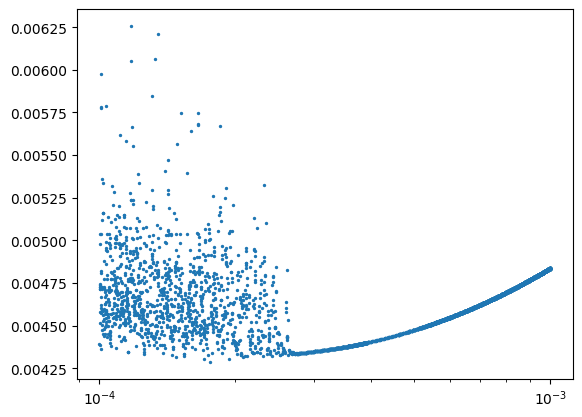

In [13]:
N=100 #Nombre de pas de temps
dT=1# taille du pas detemps
m_min =-4
m_max=-3
m_step=0.001
seuil=1e8 #seuil de distance pour considérer que l'équation converge
nb_esp_test=3 #nombre d'espèces testées pour l'initialisation
y0 = jnp.ones(S)/S  #état initial: un vecteur de taille S   

points=glv.sweep_m_values(N,dT,r,A,y0,m_min,m_max,m_step,seuil,reverse=False)
lm,lval=zip(*points)
plt.scatter(lm,lval,s=2)
plt.xscale('log')
plt.show()


Generating different initial conditions

In [5]:
N=100 #Nombre de pas de temps
dT=1# taille du pas detemps
m_min =-4
m_max=-3.5
m_step=0.01
seuil=1e8 #seuil de distance pour considérer que l'équation converge
nb_esp_test=3#nombre d'espèces testées pour l'initialisation
y0 = jnp.ones(S)/S  #état initial: un vecteur de taille S   


In [ ]:

results=glv.y0_exploration_sweep(N,dT,r,A,y0,m_min,m_max,m_step,seuil,nb_esp_test,reverse=False)


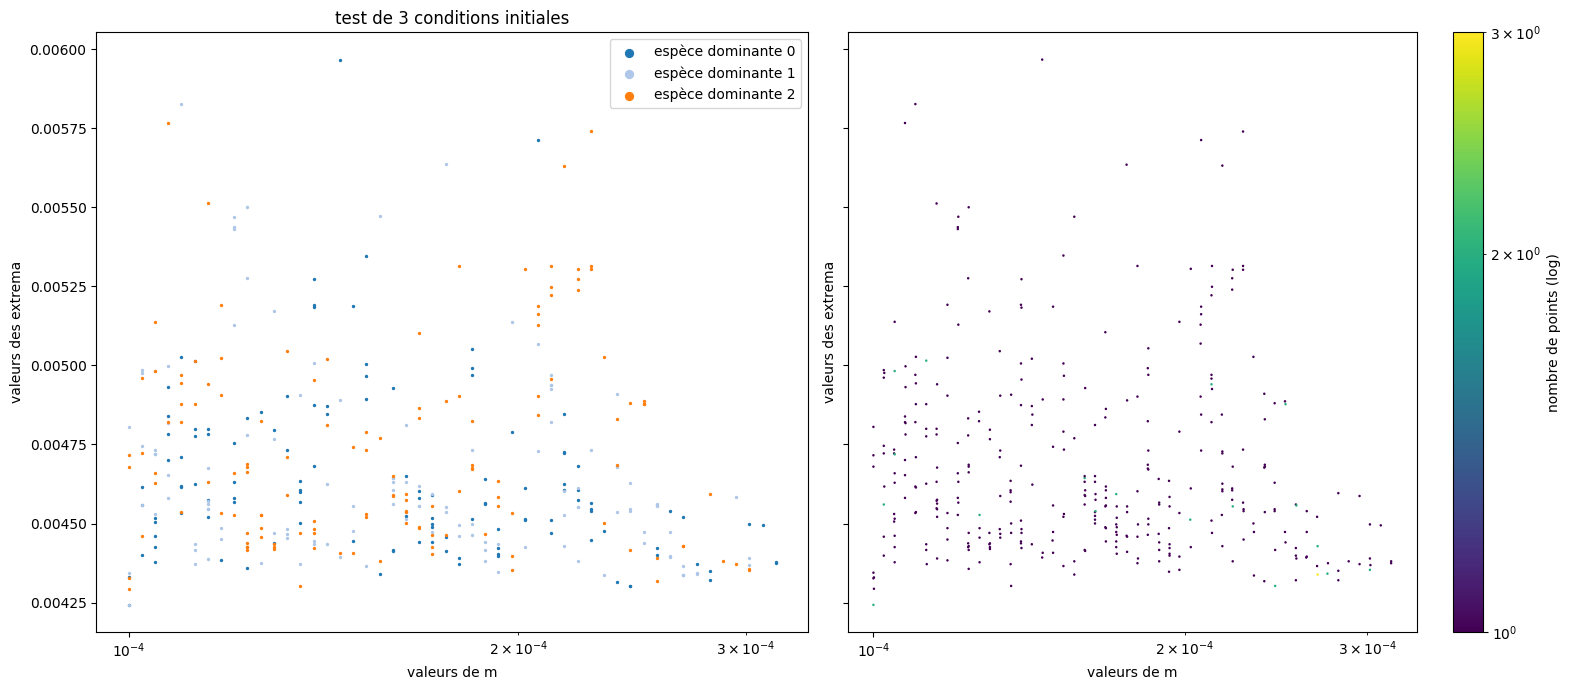

In [11]:
fig,axes=plt.subplots(1,2,layout='tight',sharey=True,figsize=(16,7))
cm1=plt.get_cmap("viridis",len(results))
cm2=plt.get_cmap("tab20")
lm=[]
lval=[]

for idx,esp in enumerate(results):
    lm.extend(esp[0])
    lval.extend(esp[1])
    axes[0].scatter(esp[0],esp[1],s=2,color=cm2(idx),label=f"espèce dominante {idx}")
    
axes[0].set_xlabel('valeurs de m')
axes[0].set_ylabel('valeurs des extrema')
axes[0].set_xscale('log')
axes[0].legend(markerscale=4)
axes[0].set_title(f"test de {nb_esp_test} conditions initiales")

hb=axes[1].hexbin(lm,lval,gridsize=500,cmap="viridis",xscale='log',bins='log',mincnt=1)
axes[1].set_xlabel('valeurs de m')
axes[1].set_ylabel('valeurs des extrema')
fig.colorbar(hb, ax=axes[1], label='nombre de points (log)')

plt.show()

Distinguishing equilibria using Bray Curtis dissimilarity

m=1.0000e-05, extrema value=4.3337e-03
m=1.0000e-05, extrema value=4.3206e-03
m=1.0000e-05, extrema value=5.1557e-03
m=1.0000e-05, extrema value=4.5282e-03
distance to previous point: 5.1718e+00
m=1.0235e-05, extrema value=5.1396e-03
m=1.0235e-05, extrema value=5.0991e-03
m=1.0235e-05, extrema value=5.1190e-03
m=1.0235e-05, extrema value=4.8838e-03
m=1.0235e-05, extrema value=5.8901e-03
distance to previous point: 3.3561e+00
m=1.0476e-05, extrema value=5.3026e-03
m=1.0476e-05, extrema value=5.4044e-03
m=1.0476e-05, extrema value=5.2762e-03
m=1.0476e-05, extrema value=5.2809e-03
m=1.0476e-05, extrema value=4.7133e-03
m=1.0476e-05, extrema value=5.7561e-03
distance to previous point: 5.8600e+00
m=1.0723e-05, extrema value=4.8476e-03
m=1.0723e-05, extrema value=5.3395e-03
m=1.0723e-05, extrema value=5.2006e-03
m=1.0723e-05, extrema value=5.6957e-03
m=1.0723e-05, extrema value=4.6146e-03
m=1.0723e-05, extrema value=4.7579e-03
m=1.0723e-05, extrema value=4.5806e-03
distance to previous poin

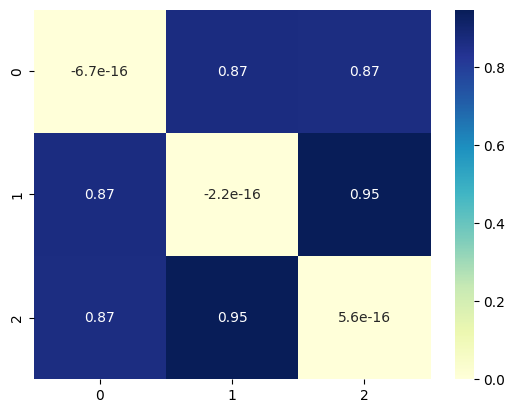

In [ ]:
diss=glv.equilibrium_distinction(N,dT,r,A,y0,m_min,m_max,m_step,seuil,nb_esp_test,reverse=False)
sns.heatmap(diss, annot=True)
plt.show()

Conclusion: over a certain m threshold, all initial conditions arrive to the same equilibrium

PLotting Kullback-leibler divergence

m=1.0000e-05, extrema value=5.2738e-03
m=1.0000e-05, extrema value=5.1688e-03
m=1.0000e-05, extrema value=5.1691e-03
m=1.0000e-05, extrema value=5.0420e-03
distance to previous point: 3.3029e+00
m=1.0235e-05, extrema value=5.8317e-03
m=1.0235e-05, extrema value=4.4090e-03
m=1.0235e-05, extrema value=4.5676e-03
m=1.0235e-05, extrema value=4.5672e-03
m=1.0235e-05, extrema value=5.1538e-03
distance to previous point: 5.9178e+00
m=1.0476e-05, extrema value=4.6358e-03
m=1.0476e-05, extrema value=5.0855e-03
m=1.0476e-05, extrema value=4.9039e-03
m=1.0476e-05, extrema value=5.0412e-03
m=1.0476e-05, extrema value=4.9648e-03
m=1.0476e-05, extrema value=4.9707e-03
m=1.0476e-05, extrema value=4.9299e-03
m=1.0476e-05, extrema value=5.2125e-03
distance to previous point: 6.6502e+00
m=1.0723e-05, extrema value=4.5650e-03
m=1.0723e-05, extrema value=4.8609e-03
m=1.0723e-05, extrema value=4.7894e-03
m=1.0723e-05, extrema value=5.4483e-03
distance to previous point: 7.3194e+00
m=1.0975e-05, extrema val

ValueError: setting an array element with a sequence. The requested array has an inhomogeneous shape after 1 dimensions. The detected shape was (2,) + inhomogeneous part.

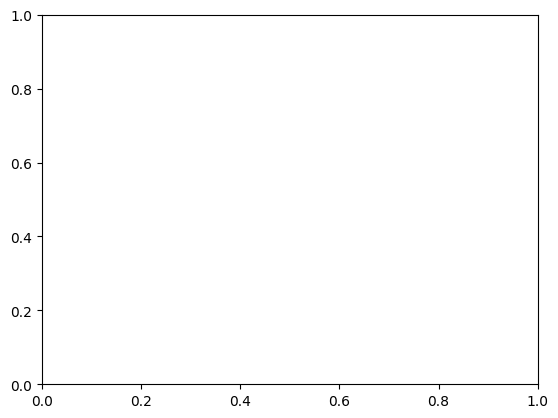

In [ ]:
N=100
dT=1
y0=jnp.ones(S)*1/S
m_min=-5
m_max=-4
m_step=0.01
seuil=5*1e2
m_values = jnp.arange(m_min, m_max, step=m_step)#le vecteur de valeurs des exposant de m
m_values=[10**m for m in m_values]
l=glv.sweep_m_values(N,dT,r,A,y0,m_min,m_max,m_step,seuil,reverse=False,return_yf=True)
plt.plot(m_values,l)
plt.xlabel('Immigration rate (m)')
plt.ylabel('Kullback Leibler divergence')
plt.xscale('log')
plt.yscale('log')
plt.show()

SAD histogramm

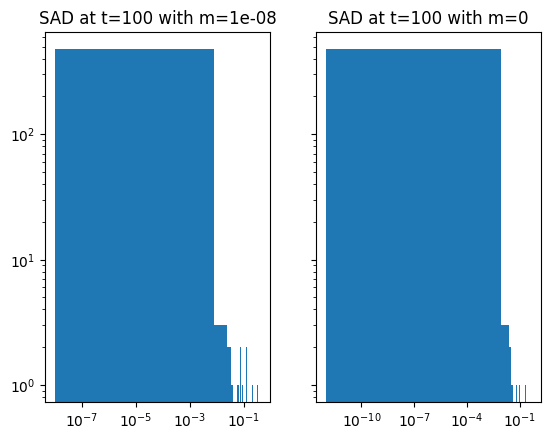

0.00013481039161722386


In [ ]:
"""
On regarde les SAD de l'état final avec et sans immigration

"""
N=100
dT=1
r=1
m=1e-8
y0=jnp.ones(S)*1/S

fig,axes=plt.subplots(1,2,sharey=True)#tight_layout=True

tzero,yzero=glv.solve(N, dT, r, A, 0, y0, rtol=1e-6, atol=1e-9, threshold=1e-12)#solution interne associée
ts, ys = glv.solve(N, dT, r, A, m, y0)

axes[0].hist(ys[-1],bins=50)
axes[0].set_title(f"SAD at t={N} with m={m}")
axes[0].set_xscale('log')
axes[1].hist(yzero[-1],bins=50)
axes[1].set_title(f"SAD at t={N} with m=0")
axes[1].set_xscale('log')


plt.yscale('log')
plt.show()
print("dissymétrie Bray Curtis entre les distributions=",glv.BC_dissimilarity(yzero[-1],ys[-1]))

Comparing  with and without immigration using Kl divergence

m=1.0000e-04, extrema value=5.1012e-03
distance to previous point: 2.3867e+00
m=1.0023e-04, extrema value=4.9546e-03
m=1.0023e-04, extrema value=5.0830e-03
m=1.0023e-04, extrema value=5.0760e-03
m=1.0023e-04, extrema value=5.6928e-03
m=1.0023e-04, extrema value=4.6965e-03
m=1.0023e-04, extrema value=4.7430e-03
m=1.0023e-04, extrema value=4.7325e-03
m=1.0023e-04, extrema value=4.8303e-03
distance to previous point: 3.0633e+00
m=1.0046e-04, extrema value=4.6179e-03
m=1.0046e-04, extrema value=4.6736e-03
m=1.0046e-04, extrema value=4.6580e-03
m=1.0046e-04, extrema value=4.7134e-03
m=1.0046e-04, extrema value=4.5018e-03
m=1.0046e-04, extrema value=5.0235e-03
m=1.0046e-04, extrema value=4.8109e-03
distance to previous point: 4.0302e+00
m=1.0069e-04, extrema value=4.8458e-03
m=1.0069e-04, extrema value=4.4693e-03
m=1.0069e-04, extrema value=5.4083e-03
distance to previous point: 3.4223e+00
m=1.0093e-04, extrema value=4.4926e-03
m=1.0093e-04, extrema value=5.1969e-03
m=1.0093e-04, extrema val

AttributeError: 'Axes' object has no attribute 'xscale'

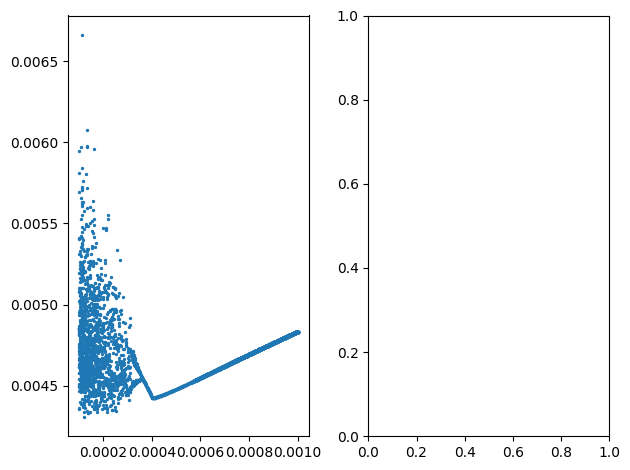

In [ ]:
""" 
On compare la distance de KL entre l'état final avec et sans immigration
"""
N=100 #Nombre de pas de temps
dT=1# taille du pas detemps
m_min =-4
m_max=-3
m_step=0.001
seuil=1e8 #seuil de distance pour considérer que l'équation converge
y0 = jnp.ones(S)/S  #état initial: un vecteur de taille S   
m_min =-4
m_max=-3
m_step=0.001
tzero,yzero=glv.solve(N, dT, r, A, 0, y0, rtol=1e-6, atol=1e-9, threshold=1e-12)#solution interne associée
m_values=jnp.logspace(m_min,m_max,int((m_max-m_min)/m_step))

ldist=[]
for m in m_values:
    ts, ys = glv.solve(N, dT, r, A, m, y0)
    ldist.append(glv.kl_divergence(yzero,ys))


points=glv.sweep_m_values(N,dT,r,A,y0,m_min,m_max,m_step,seuil,reverse=False)
lm,lval=zip(*points)


AttributeError: module 'glv' has no attribute 'point_inflexion'

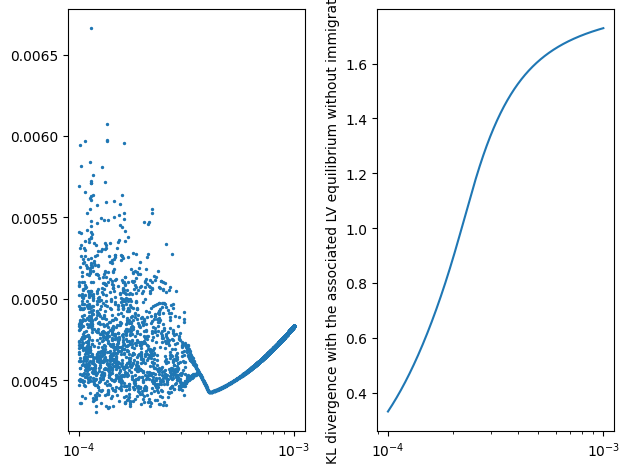

In [30]:

fig,axes=plt.subplots(1,2,tight_layout=True)
axes[0].scatter(lm,lval,s=2)
axes[0].set_xscale('log')

axes[1].plot(m_values,ldist)
axes[1].set_xscale('log')
#plt.xlabel('valeurs de m')
axes[1].set_ylabel('KL divergence with the associated LV equilibrium without immigration')

l=glv.point_inflexion(lval)
for k in l:
    axes[0].vlines(k,color='r')
    axes[1].vlines(k,color='r')
plt.show()

La différence est minimale en régime chaotique et augment avec m jusqu'à saturer quand on arrive à l'état d'équilibre

Comparing simultaneous equilibria

In [ ]:
""" 
Au préalable, afficher le diagramme de biffurcation avec suffisament de résolution pour pouvoir distinguer les équilibres multiples
prend en argument un m où il y a plusieurs équilibres, et calcule la distance de Bray Curtis entre ces équilibres"""



Retrieving net interaction biases

In [ ]:
Z=A*1/sig-mu
lzi=[]
for k in Z:
    lzi.append(sum(k))
points=glv.sweep_m_values(N,dT,r,A,y0,m_min,m_max,m_step,seuil,reverse=False)
count,bins=np.histogram()



Total Abundance 

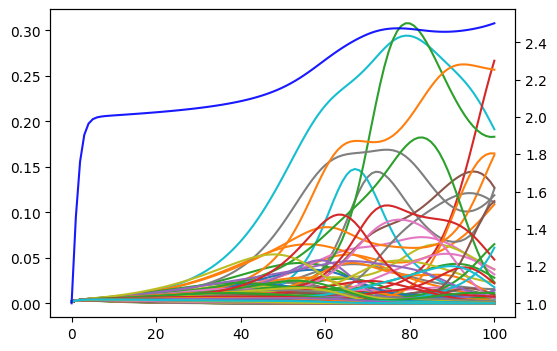

In [ ]:
""" 
On affiche l'abondance totale en bleu dans le profil d'abondances en fonction du temps
"""
somme=jnp.sum(ys,axis=1)
fig,ax1=plt.subplots(figsize=(6,4))
ax1.plot(ts,ys)
ax2=ax1.twinx()
ax2.plot(ts, somme,color='blue',alpha=0.9)
#plt.yscale('log')
plt.show()

Adiabatic mu sweep

In [ ]:
N=1000 #Nombre de pas de temps
dT=1# taille du pas detemps
y0 = jnp.ones(S)/S  #état initial: un vecteur de taille S    
mu_min =0
mu_max=3
mu_step=0.1
mu_values = jnp.arange(mu_min, mu_max, mu_step)
extrema_values_over_lambda=[]#on va mesurer le caractère chaotique de la dynamique en mesurant le nombre d'extrema, comme dans un diagramme d'orbites
for mu in mu_values:
    mu_previous=0                 
    ts,ys = glv.solve_log_RK45(N=N, dT=dT, r=r, A=A+(mu-mu_previous), m=m, y0=y0)#on résout le système pour une certaine valeur de m 
    mu_previous=mu                         
    y0=ys[-1] # Use the last state as the initial condition for the next run 
    mean_abundances = glv.extract_trajectory(ys)#on extrait l'abondance moyenne à chaque pas de temps
    extrema_values = glv.extrema_ammount(mean_abundances)#on compte le nombre d'extrema dans l'abondance moyenne
    extrema_values_over_lambda.append(extrema_values)
    for val in extrema_values:
        print(f"mu={mu:.4e}, extrema value={val:.4e}")
        plt.plot(mu, val, 'o', color='blue',markersize=1)
plt.xlabel('Average interaction (mu)')
plt.ylabel('Extrema values of mean abundance over mu')
#plt.yscale('log')
#plt.xscale('log')
plt.show()


NameError: name 'S' is not defined